# Weather Trend Forecasting
## Notebook 06: Climate by region, air quality and spatial patterns

Three questions:
1. **Climate patterns by region:** how do temperature, rain and humidity differ between continents and latitude bands,
   and when do the seasons peak?
2. **Air quality vs weather:** which weather conditions go with cleaner or dirtier air?
3. **Spatial patterns:** where is the air dirtiest, and how far apart can two cities be and still have similar weather
   on the same day?

Feature importance with several techniques is in notebook 04, where it explains the forecasting models.

Notes on the data (see notebook 01): the analysis uses the 185 locations kept after cleaning, one reading per day.
Every regional figure is an average of locations, so regions with more capitals (Europe, Africa) are covered better
than Oceania or South America. All readings are snapshots at one time of day, which drifted by about 6 hours over the period.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG = Path('../reports/figures')
PROC = Path('../data/processed')
METRICS = Path('../reports/metrics')
METRICS.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GREY = '#8a8984'
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

In [2]:
df = pd.read_csv(PROC / 'weather_clean.csv', parse_dates=['date'])
df = df.sort_values(['country', 'location_name', 'date']).reset_index(drop=True)
df['loc'] = df['location_name'] + ', ' + df['country']
df['month'] = df['date'].dt.month
df['wet'] = df['precip_mm'] > 0
AQ = {'air_quality_Carbon_Monoxide': 'CO', 'air_quality_Ozone': 'O3', 'air_quality_Nitrogen_dioxide': 'NO2',
      'air_quality_Sulphur_dioxide': 'SO2', 'air_quality_PM2.5': 'PM2.5', 'air_quality_PM10': 'PM10'}
df = df.rename(columns=AQ)
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
print(df.shape)

(161377, 41)


## 1. Climate patterns by region

### By continent

Per location first (so that each capital counts once), then averaged per continent. The seasonal range is the
difference between a location's warmest and coldest calendar month.

In [3]:
clim = df.groupby(['loc', 'month'])['temperature_celsius'].mean()
loc = df.groupby('loc').agg(continent=('continent', 'first'), lat=('latitude', 'mean'), lon=('longitude', 'mean'),
                            temp=('temperature_celsius', 'mean'), humidity=('humidity', 'mean'),
                            wet=('wet', 'mean'), wind=('wind_kph', 'mean'), pm25=('PM2.5', 'median'))
loc['season_range'] = clim.groupby(level=0).max() - clim.groupby(level=0).min()
loc['wet'] *= 100

cont = loc.groupby('continent').agg(locations=('temp', 'size'), mean_temp_C=('temp', 'mean'),
                                    seasonal_range_C=('season_range', 'mean'), wet_snapshots_pct=('wet', 'mean'),
                                    humidity_pct=('humidity', 'mean'), wind_kph=('wind', 'mean'),
                                    median_pm25=('pm25', 'median'))
cont.sort_values('mean_temp_C').round(1)

,locations,mean_temp_C,seasonal_range_C,wet_snapshots_pct,humidity_pct,wind_kph,median_pm25
continent,,,,,,,
Europe,45,14.1,21.6,26.2,69.5,11.9,11.8
South America,11,17.9,5.6,32.9,83.5,7.5,8.3
North America,21,22.4,5.7,42.1,84.3,13.9,9.2
Oceania,12,24.6,4.1,61.7,80.6,18.4,5.1
Africa,49,24.6,6.9,29.8,64.0,12.8,17.4
Asia,47,24.8,17.8,29.4,51.2,12.6,20.4


### By latitude band and month

Continents mix hemispheres (Africa and South America cross the equator), so latitude bands show the seasons more
clearly. Each cell is the band's mean temperature in that month minus the band's mean over the year.

saved ../reports/figures/06_season_by_latitude_band.png


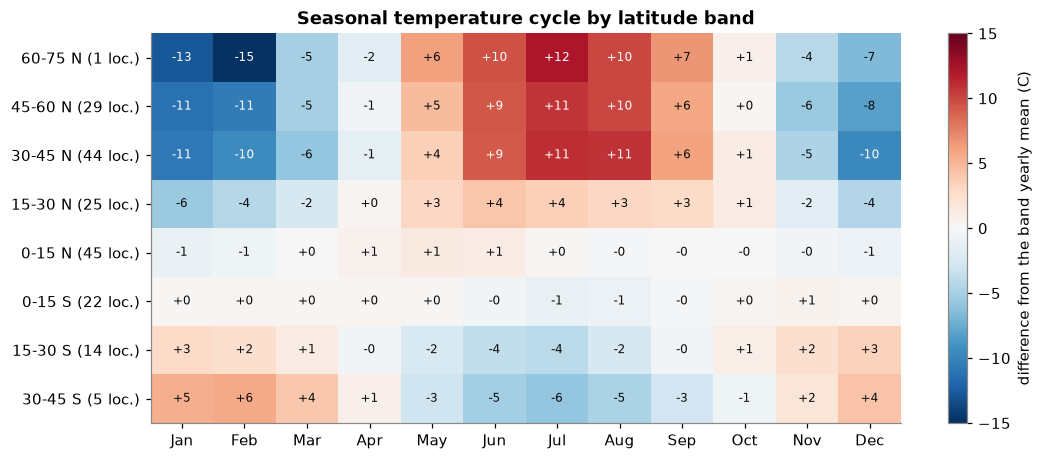

,warmest minus coldest month (C)
band,
30-45 S,11.5
15-30 S,7.4
0-15 S,1.6
0-15 N,2.4
15-30 N,9.8
30-45 N,21.8
45-60 N,21.9
60-75 N,26.9


In [4]:
band = pd.cut(df['latitude'], [-45, -30, -15, 0, 15, 30, 45, 60, 75],
              labels=['30-45 S', '15-30 S', '0-15 S', '0-15 N', '15-30 N', '30-45 N', '45-60 N', '60-75 N'])
df['band'] = band
n_loc = df.groupby('band', observed=True)['loc'].nunique()
bm = df.groupby(['band', 'month'], observed=True)['temperature_celsius'].mean().unstack()
anom = bm.sub(bm.mean(axis=1), axis=0).iloc[::-1]
labels = [f'{b} ({n_loc[b]} loc.)' for b in anom.index]

fig, ax = plt.subplots(figsize=(11, 4.6))
lim = np.ceil(np.abs(anom.values).max())
im = ax.imshow(anom.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(anom.shape[0]):
    for j in range(12):
        v = anom.values[i, j]
        ax.text(j, i, f'{v:+.0f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > lim * 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, label='difference from the band yearly mean (C)')
ax.set_title('Seasonal temperature cycle by latitude band')
save(fig, '06_season_by_latitude_band.png')
plt.show()
(bm.max(axis=1) - bm.min(axis=1)).round(1).rename('warmest minus coldest month (C)').to_frame()

saved ../reports/figures/06_rain_by_latitude_band.png


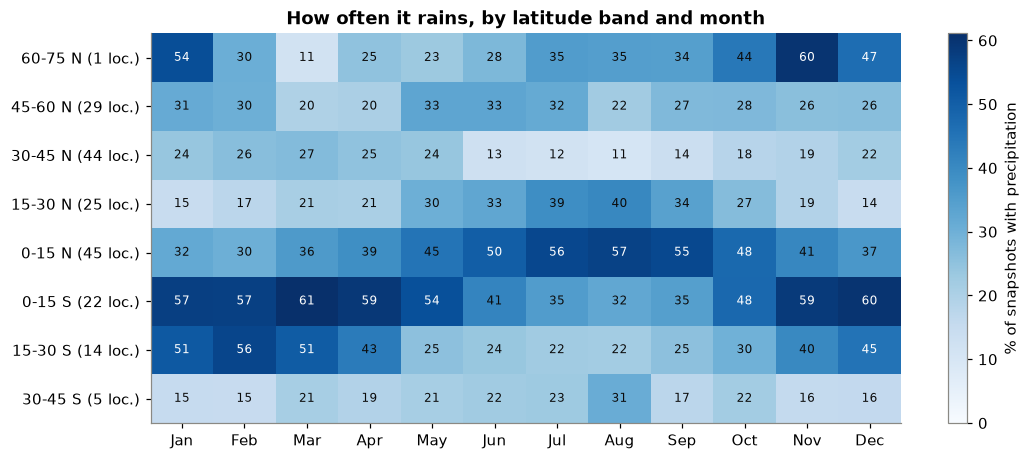

In [5]:
wet_bm = df.groupby(['band', 'month'], observed=True)['wet'].mean().unstack().iloc[::-1] * 100
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(wet_bm.values, cmap='Blues', vmin=0, aspect='auto')
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(wet_bm.shape[0]):
    for j in range(12):
        v = wet_bm.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 45 else '#0b0b0b')
fig.colorbar(im, ax=ax, label='% of snapshots with precipitation')
ax.set_title('How often it rains, by latitude band and month')
save(fig, '06_rain_by_latitude_band.png')
plt.show()

## 2. Air quality vs weather

Concentrations are in ug/m3. Spearman (rank) correlation is used because the pollutants are very skewed.

Two versions are computed, because they answer different questions:
- **Pooled:** all locations and days together. This mixes two things: differences *between* cities (a hot, dry, dusty
  capital vs a cool, wet one) and changes *within* a city from day to day.
- **Within location:** the correlation is computed separately for each location over its own days, and the median
  over all locations is shown. This removes the city differences and shows how air quality moves with the weather
  in the same place.

saved ../reports/figures/06_air_quality_vs_weather.png


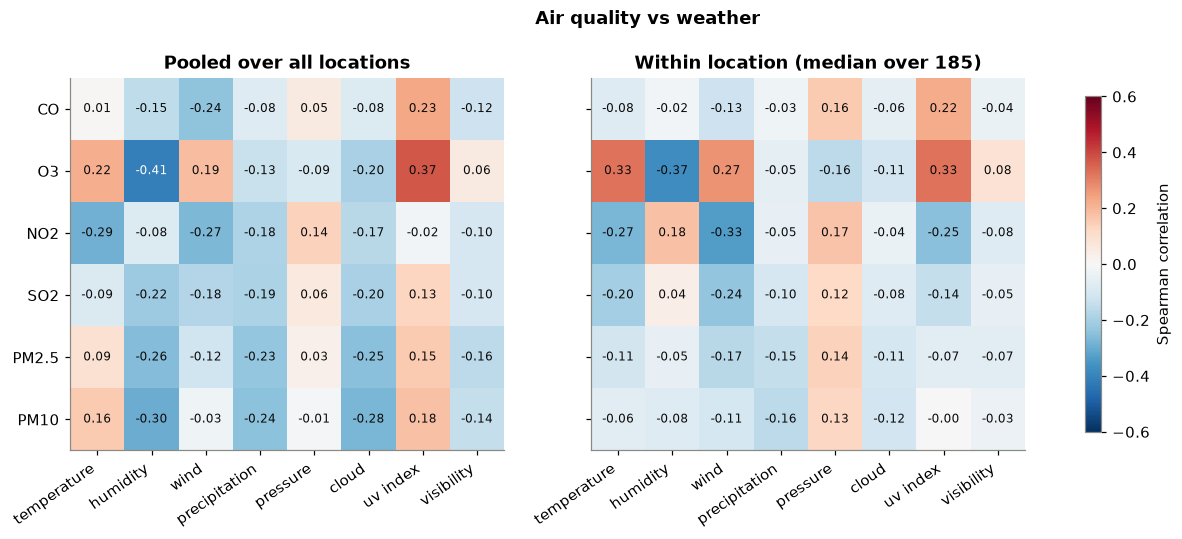

In [6]:
POLL = list(AQ.values())
WX = ['temperature_celsius', 'humidity', 'wind_kph', 'precip_mm', 'pressure_mb', 'cloud', 'uv_index', 'visibility_km']
WX_LABELS = ['temperature', 'humidity', 'wind', 'precipitation', 'pressure', 'cloud', 'uv index', 'visibility']

pooled = df[POLL + WX].corr(method='spearman').loc[POLL, WX]
per_loc = [g[POLL + WX].corr(method='spearman').loc[POLL, WX] for _, g in df.groupby('loc')]
within = pd.concat(per_loc).groupby(level=0).median().loc[POLL, WX]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, mat, title in [(axes[0], pooled, 'Pooled over all locations'), (axes[1], within, 'Within location (median over 185)')]:
    im = ax.imshow(mat.values, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
    ax.set_xticks(range(len(WX)), WX_LABELS, rotation=35, ha='right')
    ax.set_yticks(range(len(POLL)), POLL)
    ax.grid(False)
    ax.set_title(title)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.4 else '#0b0b0b')
fig.colorbar(im, ax=axes, label='Spearman correlation', shrink=0.9)
fig.suptitle('Air quality vs weather', fontweight='bold', y=1.02)
save(fig, '06_air_quality_vs_weather.png')
plt.show()

In [7]:
print('within-location correlations, median over locations:')
print(within.round(2))
print()
print('share of locations where the within-location correlation has the same sign as the median:')
signs = pd.concat([(np.sign(m) == np.sign(within)) for m in per_loc]).groupby(level=0).mean().loc[POLL, WX]
print(signs.round(2))

within-location correlations, median over locations:
       temperature_celsius  humidity  wind_kph  precip_mm  pressure_mb  cloud  uv_index  visibility_km
CO                   -0.08     -0.02     -0.13      -0.03         0.16  -0.06      0.22          -0.04
O3                    0.33     -0.37      0.27      -0.05        -0.16  -0.11      0.33           0.08
NO2                  -0.27      0.18     -0.33      -0.05         0.17  -0.04     -0.25          -0.08
SO2                  -0.20      0.04     -0.24      -0.10         0.12  -0.08     -0.14          -0.05
PM2.5                -0.11     -0.05     -0.17      -0.15         0.14  -0.11     -0.07          -0.07
PM10                 -0.06     -0.08     -0.11      -0.16         0.13  -0.12     -0.00          -0.03

share of locations where the within-location correlation has the same sign as the median:
       temperature_celsius  humidity  wind_kph  precip_mm  pressure_mb  cloud  uv_index  visibility_km
CO                    0.61      

### Two relationships in more detail

To compare cities fairly, each reading is divided by its location's median for that pollutant (1.0 = a normal day
for that city). Then the median of this ratio is shown per weather bin.

saved ../reports/figures/06_pm25_wind_ozone_uv.png


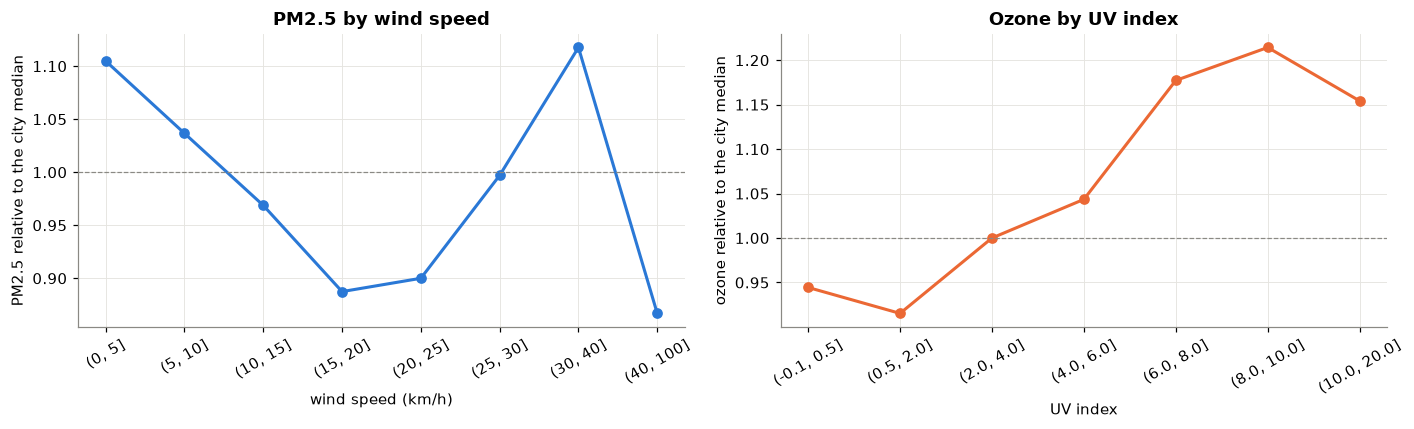

wind_kph
(0, 5]       1.10
(5, 10]      1.04
(10, 15]     0.97
(15, 20]     0.89
(20, 25]     0.90
(25, 30]     1.00
(30, 40]     1.12
(40, 100]    0.87
uv_index
(-0.1, 0.5]     0.94
(0.5, 2.0]      0.92
(2.0, 4.0]      1.00
(4.0, 6.0]      1.04
(6.0, 8.0]      1.18
(8.0, 10.0]     1.21
(10.0, 20.0]    1.15


In [8]:
for p in ['PM2.5', 'O3']:
    df[p + '_rel'] = df[p] / df.groupby('loc')[p].transform('median')

wind_bins = pd.cut(df['wind_kph'], [0, 5, 10, 15, 20, 25, 30, 40, 100])
uv_bins = pd.cut(df['uv_index'], [-0.1, 0.5, 2, 4, 6, 8, 10, 20])
pm_wind = df.groupby(wind_bins, observed=True)['PM2.5_rel'].median()
o3_uv = df.groupby(uv_bins, observed=True)['O3_rel'].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(len(pm_wind)), pm_wind.values, color=PALETTE[0], linewidth=2, marker='o')
axes[0].set_xticks(range(len(pm_wind)), [str(i) for i in pm_wind.index], rotation=30)
axes[0].set_xlabel('wind speed (km/h)')
axes[0].set_ylabel('PM2.5 relative to the city median')
axes[0].set_title('PM2.5 by wind speed')
axes[0].axhline(1, color=GREY, linewidth=0.8, linestyle='--')
axes[1].plot(range(len(o3_uv)), o3_uv.values, color=PALETTE[1], linewidth=2, marker='o')
axes[1].set_xticks(range(len(o3_uv)), [str(i) for i in o3_uv.index], rotation=30)
axes[1].set_xlabel('UV index')
axes[1].set_ylabel('ozone relative to the city median')
axes[1].set_title('Ozone by UV index')
axes[1].axhline(1, color=GREY, linewidth=0.8, linestyle='--')
fig.tight_layout()
save(fig, '06_pm25_wind_ozone_uv.png')
plt.show()
print(pm_wind.round(2).to_string())
print(o3_uv.round(2).to_string())

### US EPA air quality index by continent

The dataset includes the US EPA index (1 = good, 2 = moderate, 3 = unhealthy for sensitive groups, 4 = unhealthy,
5 = very unhealthy, 6 = hazardous).

saved ../reports/figures/06_epa_index_by_continent.png


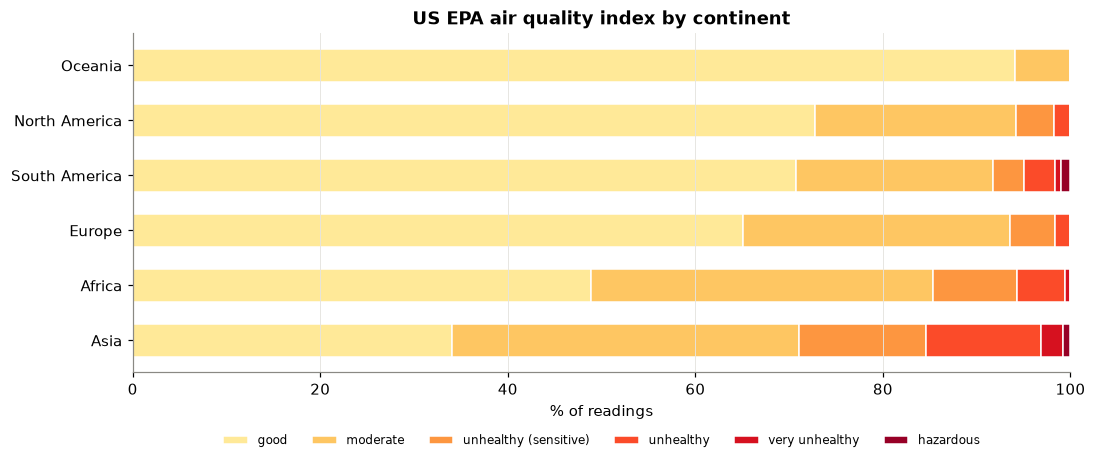

air_quality_us-epa-index,1,2,3,4,5,6
continent,,,,,,
Asia,34.0,37.1,13.5,12.3,2.3,0.8
Africa,48.9,36.5,8.9,5.2,0.5,0.0
Europe,65.1,28.4,4.7,1.6,0.1,0.0
South America,70.7,21.1,3.3,3.3,0.6,1.0
North America,72.7,21.4,4.2,1.7,0.0,0.0
Oceania,94.1,5.9,0.0,0.0,0.0,0.0


In [9]:
epa = pd.crosstab(df['continent'], df['air_quality_us-epa-index'], normalize='index') * 100
epa = epa.loc[epa[1].sort_values().index]
epa_labels = {1: 'good', 2: 'moderate', 3: 'unhealthy (sensitive)', 4: 'unhealthy', 5: 'very unhealthy', 6: 'hazardous'}
colors = plt.cm.YlOrRd(np.linspace(0.15, 0.95, 6))

fig, ax = plt.subplots(figsize=(11, 4))
left = np.zeros(len(epa))
for k, color in zip(range(1, 7), colors):
    vals = epa[k].values if k in epa else np.zeros(len(epa))
    ax.barh(epa.index, vals, left=left, color=color, height=0.6, label=epa_labels[k], edgecolor='white', linewidth=1)
    left += vals
ax.set_xlabel('% of readings')
ax.set_xlim(0, 100)
ax.set_title('US EPA air quality index by continent')
ax.legend(frameon=False, ncol=6, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.grid(axis='y', visible=False)
save(fig, '06_epa_index_by_continent.png')
plt.show()
epa.round(1)

## 3. Spatial patterns

### Where is the air dirtiest?

Median PM2.5 per location, on a log colour scale because the values span two orders of magnitude.

saved ../reports/figures/06_pm25_map.png


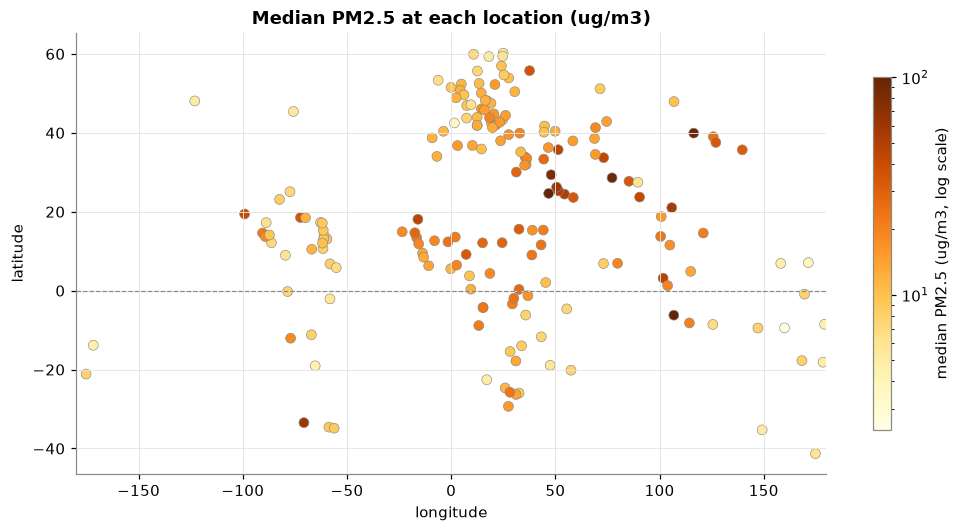

highest median PM2.5:
                          continent   pm25
loc                                       
Riyadh, Saudi Arabia           Asia  100.1
Jakarta, Indonesia             Asia   99.4
Beijing, China                 Asia   95.6
New Delhi, India               Asia   91.1
Kuwait City, Kuwait            Asia   81.4
Santiago, Chile       South America   60.5
Manama, Bahrain                Asia   58.1
Hanoi, Vietnam                 Asia   54.6

lowest median PM2.5:
                               continent  pm25
loc                                           
Honiara, Solomon Islands         Oceania   2.4
Andorra La Vella, Andorra         Europe   3.6
Majuro, Marshall Islands         Oceania   3.9
Sucre, Bolivia             South America   4.6
Funafuti, Tuvalu                 Oceania   4.6


In [10]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(figsize=(11, 5.2))
sc = ax.scatter(loc['lon'], loc['lat'], c=loc['pm25'], cmap='YlOrBr', norm=LogNorm(), s=42,
                edgecolor='#8a8984', linewidth=0.4)
ax.axhline(0, color=GREY, linewidth=0.8, linestyle='--')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_xlim(-180, 180)
ax.set_title('Median PM2.5 at each location (ug/m3)')
fig.colorbar(sc, ax=ax, label='median PM2.5 (ug/m3, log scale)', shrink=0.8)
save(fig, '06_pm25_map.png')
plt.show()

print('highest median PM2.5:')
print(loc.sort_values('pm25', ascending=False).head(8)[['continent', 'pm25']].round(1))
print()
print('lowest median PM2.5:')
print(loc.sort_values('pm25').head(5)[['continent', 'pm25']].round(1))

In [11]:
print('Spearman correlation of median PM2.5 with location climate (one row per location):')
pd.Series({c: loc['pm25'].corr(loc[c], method='spearman') for c in ['temp', 'humidity', 'wet', 'wind', 'lat']}).round(2)

Spearman correlation of median PM2.5 with location climate (one row per location):


temp        0.30
humidity   -0.52
wet        -0.40
wind       -0.11
lat         0.06
dtype: float64

### How far does a weather pattern reach?

For each location, the daily temperature anomaly is the reading minus its 31-day centred median (as in notebook 05).
Then, for every pair of locations, the correlation of their anomalies over the days both have readings is compared
with the distance between them (great-circle distance). Nearby cities share weather systems, so their anomalies
should move together; the question is how fast that fades with distance.

In [12]:
df['temp_anom'] = df['temperature_celsius'] - df.groupby('loc')['temperature_celsius'].transform(
    lambda s: s.rolling(31, center=True, min_periods=15).median())
wide = df.pivot_table(index='date', columns='loc', values='temp_anom')
corr = wide.corr(min_periods=300)

coords = loc.loc[corr.columns, ['lat', 'lon']].values
lat, lon = np.radians(coords[:, 0]), np.radians(coords[:, 1])
dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
dist = 2 * 6371 * np.arcsin(np.sqrt(a))

iu = np.triu_indices(len(corr), k=1)
pairs = pd.DataFrame({'km': dist[iu], 'r': corr.values[iu]}).dropna()
bins = [0, 250, 500, 1000, 1500, 2000, 3000, 5000, 8000, 12000, 20100]
pairs['bin'] = pd.cut(pairs['km'], bins)
binned = pairs.groupby('bin', observed=True)['r'].agg(['median', 'count'])
print('location pairs:', len(pairs))
binned.round(2)

location pairs: 17020


,median,count
bin,,
"(0, 250]",0.59,50
"(250, 500]",0.51,143
"(500, 1000]",0.32,421
"(1000, 1500]",0.15,532
"(1500, 2000]",0.05,567
"(2000, 3000]",0.01,1083
"(3000, 5000]",0.01,2653
"(5000, 8000]",0.01,4016
"(8000, 12000]",-0.00,4174


saved ../reports/figures/06_anomaly_correlation_vs_distance.png


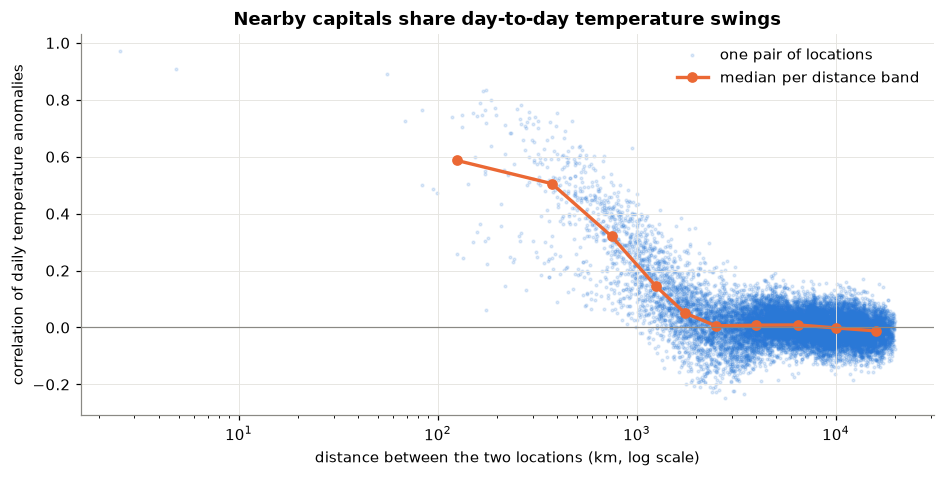

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(pairs['km'], pairs['r'], s=3, color=PALETTE[0], alpha=0.15, label='one pair of locations')
mid = [(b.left + b.right) / 2 for b in binned.index]
ax.plot(mid, binned['median'], color=PALETTE[1], linewidth=2.2, marker='o', label='median per distance band')
ax.axhline(0, color=GREY, linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('distance between the two locations (km, log scale)')
ax.set_ylabel('correlation of daily temperature anomalies')
ax.set_title('Nearby capitals share day-to-day temperature swings')
ax.legend(frameon=False, loc='upper right')
save(fig, '06_anomaly_correlation_vs_distance.png')
plt.show()

In [14]:
print('most similar pairs (highest anomaly correlation):')
names = corr.columns.values
idx = pd.DataFrame({'a': names[iu[0]], 'b': names[iu[1]], 'km': dist[iu], 'r': corr.values[iu]}).dropna()
idx.sort_values('r', ascending=False).head(6).round(2)

most similar pairs (highest anomaly correlation):


,a,b,km,r
16229,"Rome, Italy","Vatican City, Vatican City",2.53,0.97
5739,"Brazzaville, Congo","Kinshasa, Democratic Republic of Congo",4.86,0.91
5686,"Bratislava, Slovakia","Vienna, Austria",55.89,0.89
1118,"Amsterdam, Netherlands","Brussels, Belgium",175.57,0.83
13772,"Minsk, Belarus","Vilnius, Lithuania",169.99,0.83
6049,"Brussels, Belgium","Luxembourg, Luxembourg",186.52,0.80


## Summary

**Climate by region**
- Europe has the lowest mean temperature (14.1 C) and the largest seasonal range (21.6 C between warmest and
  coldest month). Asia is close behind on seasonal range (17.8 C), because it includes continental cities such as
  Ulaanbaatar and Beijing. Tropical regions have small ranges (Oceania 4.1 C, South America 5.6 C).
- By latitude band the seasonal range grows from 1.6 to 2.4 C near the equator to 21.8 C at 30 to 45 N and 26.9 C (one location only)
  at 60 to 75 N. The southern bands peak in December to February and the northern bands in June to August.
- Oceania's capitals report precipitation in 61.7% of snapshots, Europe's in 26.2%.

**Air quality vs weather (within location, median over 185 locations)**
- **Wind** goes with cleaner air for every pollutant except ozone: NO2 -0.33 (same sign in 96% of locations),
  SO2 -0.24, PM2.5 -0.17. The binned view is not a straight line, though: PM2.5 is 1.10 times the city median on
  calm days, falls to 0.89 at 15 to 20 km/h, and rises again to 1.12 at 30 to 40 km/h. Strong wind can carry
  dust; the data shows the pattern but not the cause.
- **Rain** goes with lower particles: PM10 -0.16 and PM2.5 -0.15, with the same sign in about 90% of locations.
- **Ozone** behaves differently from the other pollutants: it rises with UV (0.33) and temperature (0.33) and falls
  with humidity (-0.37). Ozone relative to the city median goes from 0.92 at low UV to 1.21 at UV 8 to 10. This
  fits the fact that ozone near the ground is formed by sunlight.
- All within-location correlations are weak to moderate (at most 0.37 in absolute value). Weather explains only
  part of the day-to-day change in air quality.

**Spatial patterns**
- The dirtiest air (median PM2.5) is in Riyadh (100.1 ug/m3), Jakarta (99.4), Beijing (95.6), New Delhi (91.1)
  and Kuwait City (81.4). The cleanest is on Pacific islands and in mountain capitals, for example Honiara (2.4)
  and Andorra La Vella (3.6).
- Across locations, median PM2.5 is lower where the air is more humid (Spearman -0.52) and where it rains more
  often (-0.40).
- On the US EPA index, Asia has the largest share of readings rated unhealthy or worse (15.4%: index 4, 5 and 6
  together), and Oceania has none.
- Nearby capitals share their day-to-day temperature swings: the median anomaly correlation is 0.59 for pairs
  closer than 250 km, 0.32 at 500 to 1,000 km, 0.05 at 1,500 to 2,000 km, and about 0 beyond 2,000 km. Weather
  systems are regional, which is also why a global average hides what happens in each place.